**Name:** Rachel Sara Mathew  |  **Sec:** G  |  **SRN:** PES2UG24CS390


# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
Name: fraud count, dtype: int64


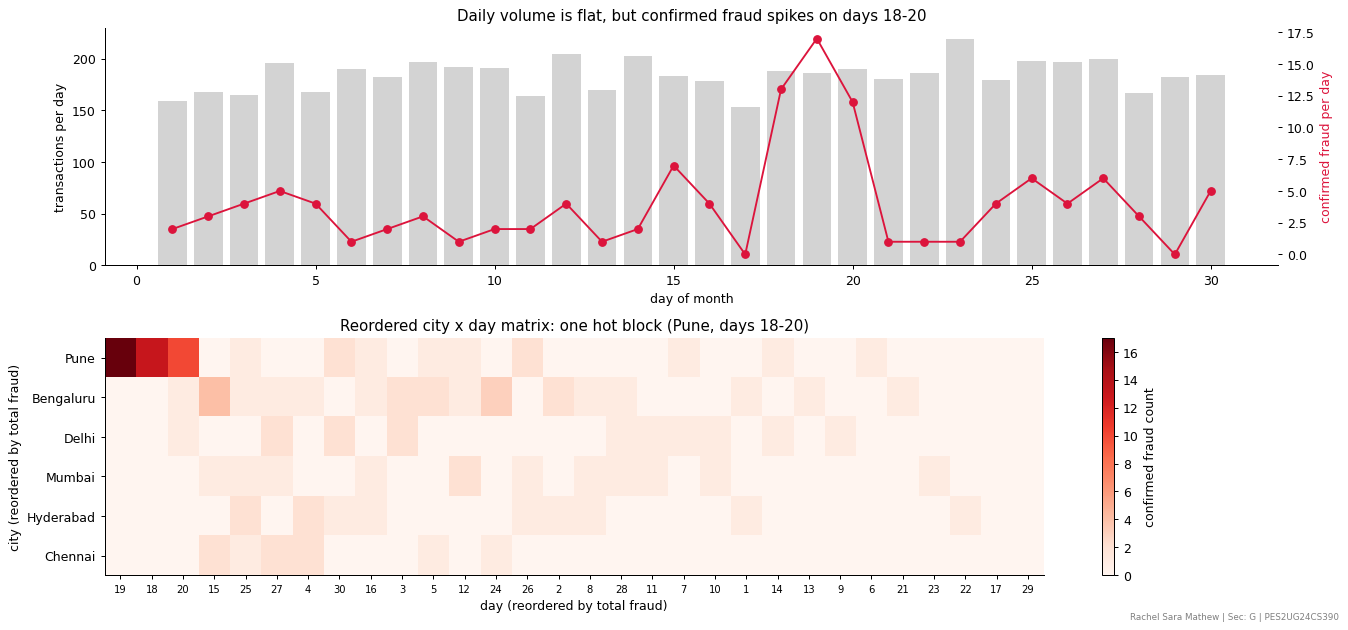

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily = tx.groupby("day").agg(n=("txn_id", "size"), fraud=("is_fraud", "sum"))
axes[0].bar(daily.index, daily.n, color="lightgrey", label="all transactions")
axes[0].set(xlabel="day of month", ylabel="transactions per day", title="Daily volume is flat, but confirmed fraud spikes on days 18-20")
ax2 = axes[0].twinx(); ax2.plot(daily.index, daily.fraud, "o-", color="crimson", label="confirmed fraud")
ax2.set_ylabel("confirmed fraud per day", color="crimson")

# TODO 2
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index, heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns, fontsize=8)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set(xlabel="day (reordered by total fraud)", ylabel="city (reordered by total fraud)", title="Reordered city x day matrix: one hot block (Pune, days 18-20)")
plt.colorbar(im, ax=axes[1], label="confirmed fraud count")

plt.tight_layout(); plt.show()

# TODO 3
print(heat.stack().sort_values(ascending=False).head(5).rename("fraud count"))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview showed that fraud is not spread evenly: 40 of the 120 confirmed frauds sit in one block, Pune on days 18-20 (17, 13 and 10 cases per day), while daily transaction volume is flat. An alert list sorted by detector score is a flat list of single transactions, with no city or day structure, so the burst would never be visible. I found it by reordering the city x day matrix by totals (Slide 39) after starting with the whole-month overview (overview first), so the hot block moved to the corner.


## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

brushed: 61 | fraud rate inside 86.9% vs overall 2.2% | captures 44.2% of all fraud


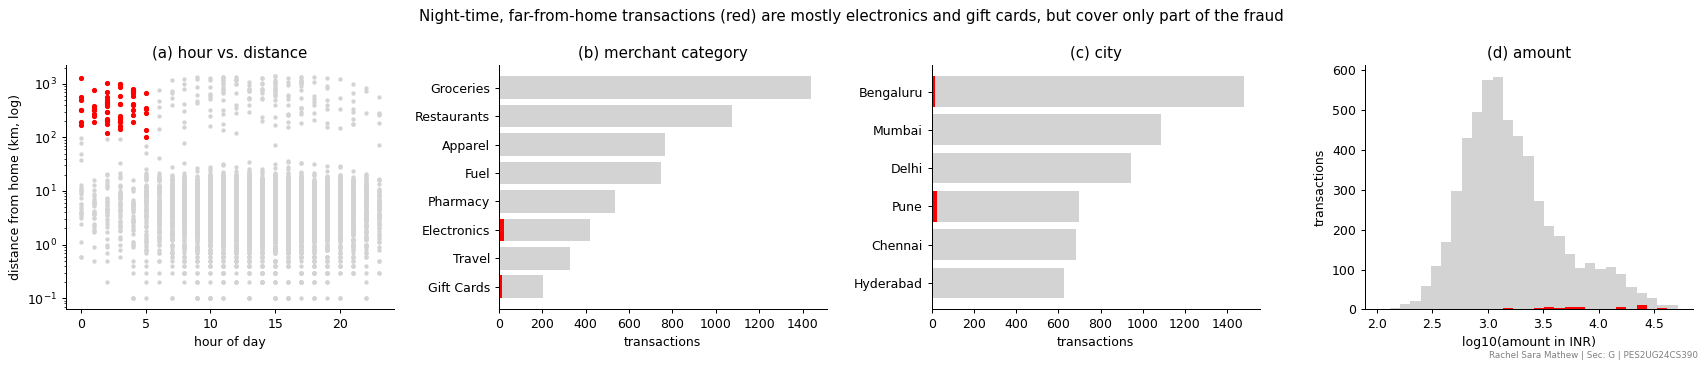

In [ ]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
a = axes[0]
a.scatter(tx.hour, tx.distance_from_home_km.clip(lower=0.1), s=6, c="lightgrey")
a.scatter(tx.hour[brush], tx.distance_from_home_km[brush], s=10, c="red")
a.set(yscale="log", xlabel="hour of day", ylabel="distance from home (km, log)", title="(a) hour vs. distance")
cats = tx.merchant_category.value_counts().index
axes[1].barh(cats, tx.merchant_category.value_counts(), color="lightgrey")
axes[1].barh(cats, brush.groupby(tx.merchant_category).sum().reindex(cats), color="red")
axes[1].set(xlabel="transactions", title="(b) merchant category"); axes[1].invert_yaxis()
cities = tx.city.value_counts().index
axes[2].barh(cities, tx.city.value_counts(), color="lightgrey")
axes[2].barh(cities, brush.groupby(tx.city).sum().reindex(cities), color="red")
axes[2].set(xlabel="transactions", title="(c) city"); axes[2].invert_yaxis()
bins = np.linspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 30)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color="lightgrey")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=bins, color="red")
axes[3].set(xlabel="log10(amount in INR)", ylabel="transactions", title="(d) amount")
fig.suptitle("Night-time, far-from-home transactions (red) are mostly electronics and gift cards, but cover only part of the fraud")

plt.tight_layout(); plt.show()

# TODO 3
rate_in, rate_all = tx.is_fraud[brush].mean(), tx.is_fraud.mean()
share = tx.is_fraud[brush].sum() / tx.is_fraud.sum()
print(f"brushed: {brush.sum()} | fraud rate inside {rate_in:.1%} vs overall {rate_all:.1%} | captures {share:.1%} of all fraud")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The brush (night, more than 100 km from home) has 61 transactions with an 86.9% fraud rate against 2.2% overall, but it captures only 44% of all fraud (53 of 120); the other 67 fraud cases fall outside it. A rule with a high rate but low coverage must not be the only control, since over half the fraud would slip through. The linked views hint at where the rest is: most of the missed fraud is in the daytime and about 40% is again in Pune, with the same electronics and gift-card categories, so the city and category panels show the rest of the fraud sits elsewhere than the night/far-away corner of the scatter plot.


## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [ ]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
def run_filter():
    return big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
times = []
for _ in range(5):
    t0 = time.perf_counter(); run_filter(); times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (per_item_us * 1e-6)

# TODO 3
t_50m = per_item_us * 1e-6 * 50_000_000
skip_pct = max(0.0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 11.0 ms -> 0.0109 us/row -> max 9,136,653 rows in 0.1 s
50M rows -> 0.55 s; must skip 81.7% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

Sampling or aggregation is a reduce technique that would keep the slider instant on 50M rows: for example plot a 1% random sample, or pre-aggregate into bins (counts per score x amount cell, hexbin or data-cube). The analyst loses individual records: with only 2% fraud, a sample or coarse bin can drop or hide the rare fraud cases, and you can no longer click a single transaction without going back to the full table.


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

 threshold  alerts  TP   FP  FN  precision  recall    F1
      0.05    2012 114 1898   6      0.057   0.950 0.107
      0.10    1167 111 1056   9      0.095   0.925 0.172
      0.15     786 110  676  10      0.140   0.917 0.243
      0.20     596 106  490  14      0.178   0.883 0.296
      0.25     471 105  366  15      0.223   0.875 0.355
      0.30     401 104  297  16      0.259   0.867 0.399
      0.35     355 104  251  16      0.293   0.867 0.438
      0.40     319 104  215  16      0.326   0.867 0.474
      0.45     283 104  179  16      0.367   0.867 0.516
      0.50     260 101  159  19      0.388   0.842 0.532
      0.55     235  97  138  23      0.413   0.808 0.546
      0.60     215  96  119  24      0.447   0.800 0.573
      0.65     197  94  103  26      0.477   0.783 0.593
      0.70     189  93   96  27      0.492   0.775 0.602
      0.75     170  87   83  33      0.512   0.725 0.600
      0.80     144  84   60  36      0.583   0.700 0.636
      0.85     128  79   49  41

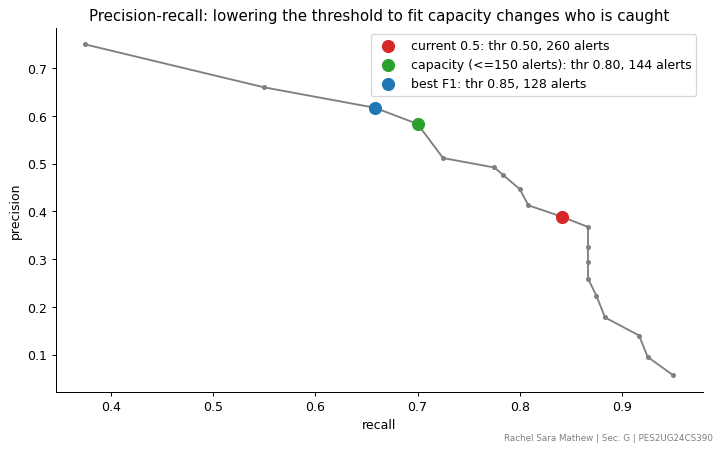

In [ ]:
rows = []
# TODO 1
for thr in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flagged_m = tx.detector_score >= thr
    tp = int((flagged_m & (tx.is_fraud == 1)).sum()); fp = int((flagged_m & (tx.is_fraud == 0)).sum())
    fn = int((~flagged_m & (tx.is_fraud == 1)).sum())
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn)
    f1 = 2 * prec * rec / (prec + rec) if tp else 0.0
    rows.append(dict(threshold=thr, alerts=tp + fp, TP=tp, FP=fp, FN=fn, precision=prec, recall=rec, F1=f1))

pr = pd.DataFrame(rows)

# TODO 2
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.F1.idxmax()]
current = pr[pr.threshold == 0.5].iloc[0]
print(pr.round(3).to_string(index=False))

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", color="gray", ms=3)
for lab, r, col in [("current 0.5", current, "tab:red"), ("capacity (<=150 alerts)", capacity_choice, "tab:green"), ("best F1", best_f1, "tab:blue")]:
    ax.scatter(r.recall, r.precision, s=90, color=col, zorder=3, label=f"{lab}: thr {r.threshold:.2f}, {int(r.alerts)} alerts")
ax.set(xlabel="recall", ylabel="precision", title="Precision-recall: lowering the threshold to fit capacity changes who is caught")
ax.legend(); plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: set the threshold to {capacity_choice.threshold:.2f} ({int(capacity_choice.alerts)} alerts/month, "
      f"precision {capacity_choice.precision:.0%}, recall {capacity_choice.recall:.0%}); the best-F1 threshold is {best_f1.threshold:.2f} "
      f"({int(best_f1.alerts)} alerts, F1 {best_f1.F1:.2f}).")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The Head of Fraud Ops should decide, not the model. The best-F1 point (0.85, 128 alerts, F1 0.64) treats a false alarm and a missed fraud as equally bad and knows nothing about investigator capacity, whereas the capacity-constrained choice (0.80, 144 alerts, precision 58%, recall 70%) is within the 150-alert limit and catches more fraud. The costs of a missed fraud, a wasted review and an annoyed customer are business judgements; visual analytics keeps the human in the loop, seeing the precision-recall trade-off and steering the parameter, because the model cannot weigh those context-dependent costs.


## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [ ]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3].copy()
fig1 = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                  hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
                  color_discrete_map={"confirmed fraud": "crimson", "legitimate": "lightgrey"},
                  title="Flagged transactions (score >= 0.3): hover for details, drag to select")
fig1.update_layout(dragmode="select")
fig1.show()

# TODO 2
sun = tx.groupby(["city", "merchant_category"]).agg(n=("txn_id", "size"), fraud_rate=("is_fraud", "mean")).reset_index()
fig2 = px.sunburst(sun, path=["city", "merchant_category"], values="n", color="fraud_rate",
                   color_continuous_scale="Reds", title="Drill down: city -> merchant category (colour = fraud rate)")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

A tooltip shows one case at a time, so to get an overview of the 400 flagged cases an investigator would have to hover over hundreds of points and remember what each one showed; this overloads working memory and hides patterns that only appear when many cases are seen together. The city x day heat map and the linked/brushed views from Tasks 1 and 2 (or the sunburst) fix this by showing the whole population at once, with details on demand then reserved for individual cases.


## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

in window: 107 txns, fraud rate 37.4% | outside: fraud rate 1.48% | chi2 = 619.3, p = 1.06e-136
Pune, days 18-20           n =   107  fraud rate = 37.38%
Pune, other days           n =   593  fraud rate = 1.85%
Other cities, days 18-20   n =   457  fraud rate = 0.44%
Everything else            n =  4363  fraud rate = 1.54%
Verdict: hypothesis SUPPORTED. Fraud is concentrated in Pune on days 18-20 (37% vs 1.5%, p = 1.1e-136), and neither Pune on other days nor other cities on those days is elevated, so it is not a city-wide or a date-wide effect.


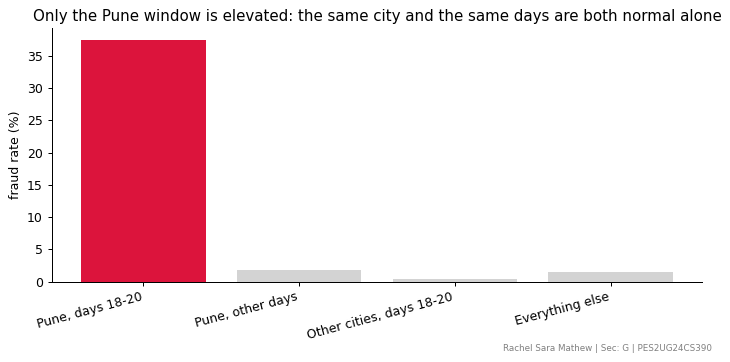

In [ ]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# H: the fraud burst is concentrated in Pune on days 18-20
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
ct = pd.crosstab(in_window, tx.is_fraud)
chi2, p, _, _ = chi2_contingency(ct)
r_in, r_out = tx.is_fraud[in_window].mean(), tx.is_fraud[~in_window].mean()
print(f"in window: {in_window.sum()} txns, fraud rate {r_in:.1%} | outside: fraud rate {r_out:.2%} | chi2 = {chi2:.1f}, p = {p:.2e}")

# TODO 3
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = (tx.city != "Pune") & ~tx.day.between(18, 20)
groups = {"Pune, days 18-20": in_window, "Pune, other days": same_city_other_days,
          "Other cities, days 18-20": other_cities_same_days, "Everything else": rest}
rates = {k: tx.is_fraud[m].mean() * 100 for k, m in groups.items()}
for k, m in groups.items():
    print(f"{k:26s} n = {m.sum():5d}  fraud rate = {rates[k]:.2f}%")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(rates), list(rates.values()), color=["crimson", "lightgrey", "lightgrey", "lightgrey"])
ax.set(ylabel="fraud rate (%)", title="Only the Pune window is elevated: the same city and the same days are both normal alone")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
plt.tight_layout(); plt.show()

# TODO 5
print(f"Verdict: hypothesis SUPPORTED. Fraud is concentrated in Pune on days 18-20 ({r_in:.0%} vs {r_out:.1%}, p = {p:.1e}), "
      "and neither Pune on other days nor other cities on those days is elevated, so it is not a city-wide or a date-wide effect.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

Counter-example search (b), other cities on the same days, would have killed the one-city idea if it had come out differently: the rate there is only 0.44%, but if those cities had spiked too the cause would be a date-wide effect (a general attack wave, a detector or data fault, or a holiday) and not a ring in one city. Search (a), Pune on other days, would also have shown a Pune-wide weakness (such as a compromised merchant terminal) rather than a short burst; it came out at 1.85%, close to normal, so both alternatives are rejected.


## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month's fraud was concentrated: 40 of the 120 confirmed cases (37% of Pune's 107 transactions on days 18-20 versus 1.5% elsewhere, p about 1e-136) came from Pune on days 18-20, and the 0.5 threshold gave 260 alerts, above our 150 capacity. I recommend moving the threshold to 0.80 (144 alerts, 58% precision, 70% recall), because it fits capacity and catches more fraud than the best-F1 point at 0.85; the Head of Fraud Ops keeps the final say, with the precision-recall plot as the steering view. The first interactive view to build should be the linked overview (city x day heat map brushed with the scatter), following overview first and fast dynamic queries within the 0.1 s budget (the filter takes about 0.45 s for 50M rows, so pre-aggregate about 78% of rows). We should also add a feedback loop (Slide 51): investigators' confirmed or rejected alerts are fed back as new labels so that the detector is retrained next month.
